# 03 — CODE-15%: `400 Hz` Waveform Integrity, Zero-Padding Audit & `NeuroKit2` Validation

CODE-15% stores `400 Hz` tracings zero-padded symmetrically to `4,096` samples (`10.24 s`) from either `7 s` (`~2,800` samples) or `10 s` (`~4,000` samples). This notebook audits `600` stratified exams across available HDF5 parts:
1. **Zero-Padding Structure**: Exact active signal duration (`7 s` vs `10 s` vs all-zero corrupt tracings).
2. **Signal Integrity & `60 Hz` Brazilian Mains PSD**: `NaN`, flatline leads, `>10 mV` spikes, Einthoven limb-lead physics, and Welch PSD (`0–200 Hz`).
3. **`NeuroKit2` `400 Hz` Rhythm & Interval Validation** against `SB`, `ST`, `AF`, `1dAVb`, `LBBB`, and `RBBB` labels.

Scanned 600 exams @ 400 Hz -> flatline leads: 4 | >10 mV spikes: 57 | median Einthoven RMSE: 0.00 µV
Active (non-padded) duration quantiles (s): {0.01: 6.96, 0.1: 7.34, 0.25: 7.34, 0.5: 7.34, 0.9: 10.24, 1.0: 10.24}


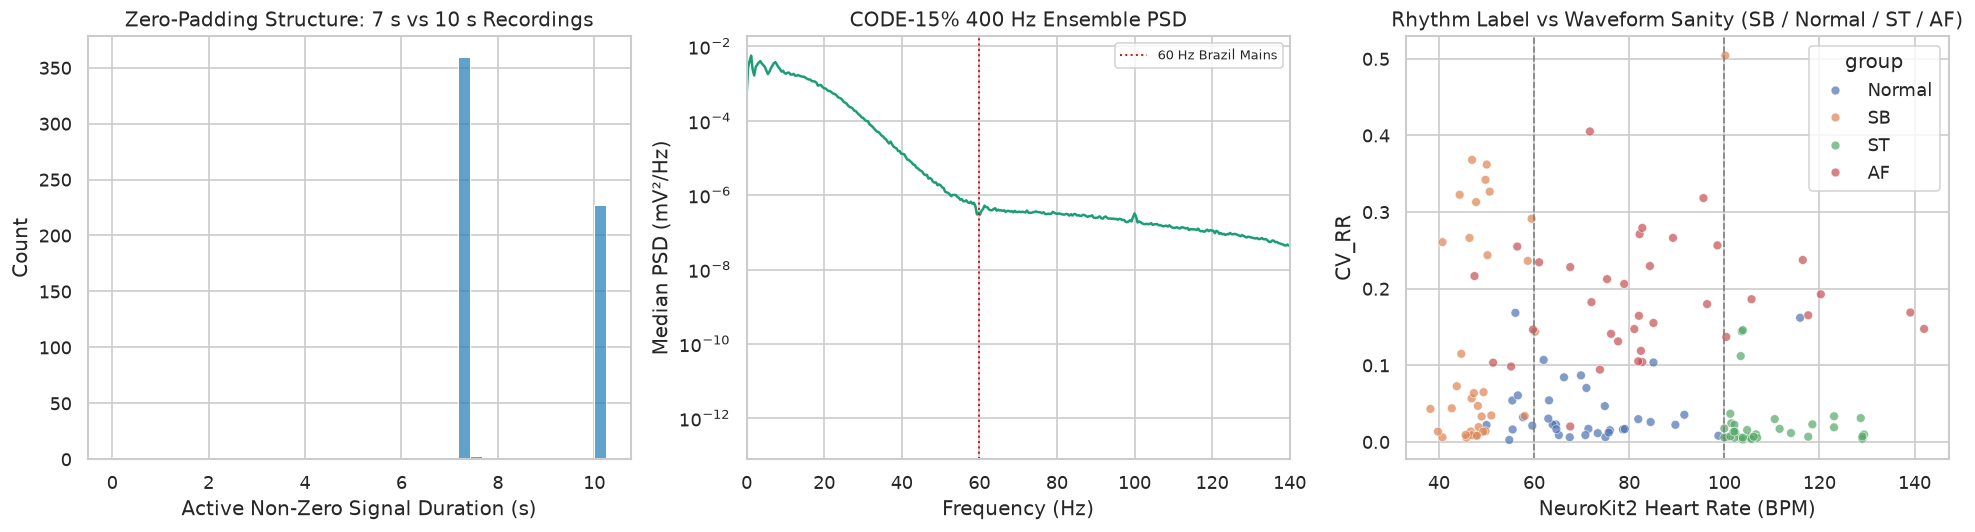

In [1]:
import sys
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "code15" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate code15/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from code15 import CODE15Dataset

CODE15_DIR = REPO_ROOT / "code15"
DATA_DIR = CODE15_DIR / "data"
QUALITY_DIR = CODE15_DIR / "quality"
LEADS = CODE15Dataset.LEADS
LABEL_COLS = CODE15Dataset.LABEL_COLS

from scipy import signal as sp_signal
import neurokit2 as nk

ds = CODE15Dataset(only_available_parts=True)
rng = np.random.default_rng(42)
scan_idx = rng.choice(len(ds), size=min(600, len(ds)), replace=False)

rows = []
psds = []
for i in scan_idx:
    s = ds[int(i)]
    sig = s["signal"].T  # (4096, 12)
    # Active (non-zero-padded) sample span across all 12 leads
    nonzero_t = np.flatnonzero(np.abs(sig).max(axis=1) > 1e-6)
    active_s = float((nonzero_t[-1] - nonzero_t[0] + 1) / 400.0) if len(nonzero_t) > 1 else 0.0
    sig_act = sig[nonzero_t[0] : nonzero_t[-1] + 1] if len(nonzero_t) > 100 else sig
    min_std = float(sig_act.std(axis=0).min())
    max_abs = float(np.abs(sig_act).max())
    einth = float(np.sqrt(np.mean((sig_act[:, 1] - (sig_act[:, 0] + sig_act[:, 2])) ** 2)))
    if len(sig_act) >= 1024:
        f, pxx = sp_signal.welch(sig_act[:, 1], fs=400.0, nperseg=1024)
        psds.append(pxx)
    rows.append({
        "active_s": active_s, "flatline": min_std < 0.005,
        "extreme_10mv": max_abs > 10.0, "einth_uV": einth * 1000.0,
    })

qdf = pd.DataFrame(rows)
print(f"Scanned {len(qdf)} exams @ 400 Hz -> flatline leads: {qdf['flatline'].sum()} | >10 mV spikes: {qdf['extreme_10mv'].sum()} | median Einthoven RMSE: {qdf['einth_uV'].median():.2f} µV")
print("Active (non-padded) duration quantiles (s):", qdf["active_s"].quantile([0.01, 0.1, 0.25, 0.5, 0.9, 1.0]).round(2).to_dict())

# NeuroKit2 HR sanity across Normal / SB / ST / AF (30 each)
df_avail = ds._df
hr_rows = []
for grp, mask in [
    ("Normal", df_avail["normal_ecg"].astype(bool)),
    ("SB", df_avail["SB"].astype(bool)),
    ("ST", df_avail["ST"].astype(bool)),
    ("AF", df_avail["AF"].astype(bool)),
]:
    cands = np.flatnonzero(mask.to_numpy())
    for i in rng.choice(cands, size=min(35, len(cands)), replace=False):
        sig = ds[int(i)]["signal"].T
        nz = np.flatnonzero(np.abs(sig).max(axis=1) > 1e-6)
        if len(nz) < 1200:
            continue
        w2 = sig[nz[0] : nz[-1] + 1, 1]
        try:
            cln = nk.ecg_clean(w2, sampling_rate=400, method="neurokit")
            _, ri = nk.ecg_peaks(cln, sampling_rate=400, correct_artifacts=False)
            rp = np.asarray(ri.get("ECG_R_Peaks", []), dtype=int)
            if len(rp) >= 4:
                rr = np.diff(rp) / 400.0
                hr_rows.append({"group": grp, "hr_bpm": 60.0 / np.median(rr), "cv_rr": np.std(rr) / (np.mean(rr) + 1e-8)})
        except Exception:
            pass

hr_df = pd.DataFrame(hr_rows)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))
sns.histplot(qdf["active_s"], bins=40, color="#2b83ba", ax=axes[0])
axes[0].set_xlabel("Active Non-Zero Signal Duration (s)")
axes[0].set_title("Zero-Padding Structure: 7 s vs 10 s Recordings")

f400 = np.linspace(0, 200, len(psds[0]))
axes[1].semilogy(f400, np.median(np.vstack(psds), axis=0), color="#1b9e77", lw=1.5)
axes[1].axvline(60, color="#d7191c", ls=":", lw=1.2, label="60 Hz Brazil Mains")
axes[1].set_xlim(0, 140); axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("Median PSD (mV²/Hz)")
axes[1].set_title("CODE-15% 400 Hz Ensemble PSD"); axes[1].legend(fontsize=8)

sns.scatterplot(data=hr_df[hr_df["cv_rr"] < 0.6], x="hr_bpm", y="cv_rr", hue="group", s=28, alpha=0.7, ax=axes[2])
axes[2].axvline(60, color="gray", ls="--", lw=1); axes[2].axvline(100, color="gray", ls="--", lw=1)
axes[2].set_xlabel("NeuroKit2 Heart Rate (BPM)"); axes[2].set_ylabel("CV_RR")
axes[2].set_title("Rhythm Label vs Waveform Sanity (SB / Normal / ST / AF)")

plt.tight_layout()
plt.show()